# Milestone 2, Part 1: class-conditional diffusion model on DermaMNIST

Goal: train a class-conditional diffusion model on the DermaMNIST training split (28×28) and use it to generate extra images for the minority classes. Part 2 (`milestone2_2.ipynb`) retrains the classifier with these images.

Outline of the notebook:

1. Setup: check the GPU, get the official DDIM code, install the libraries, mount Google Drive.
2. Configuration: every setting of the run in one dictionary.
3. Data: load the training split, look at the class imbalance, convert the images for the model.
4. Model: a class-conditional U-Net, and a speed benchmark to choose the batch size.
5. Diffusion training: forward process, loss with classifier-free guidance, EMA, sampler, training loop.
6. Training results: loss curve and sample previews.
7. Generate synthetic images: 1,000 images for each class except nv, with the trained EMA model.

## 1. Setup

Check which GPU Colab assigned. This notebook was run on a Tesla T4.

In [ ]:
!nvidia-smi

Wed Nov 18 09:46:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Clone the official DDIM repository (`ermongroup/ddim`). We only use its `generalized_steps` function, the same DDIM sampler as in Milestone 1, Part B.

In [ ]:
!git clone https://github.com/ermongroup/ddim.git /content/ddim


Cloning into '/content/ddim'...
remote: Enumerating objects: 66, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (30/30), done.
remote: Total 66 (delta 25), reused 23 (delta 23), pack-reused 13 (from 1)
Receiving objects: 100% (66/66), 30.58 KiB | 513.00 KiB/s, done.
Resolving deltas: 100% (25/25), done.


Install the libraries:

- `diffusers` provides the U-Net and the DDPM noise schedule.
- `medmnist` provides the DermaMNIST dataset.

In [ ]:
!pip install diffusers medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [medmnist]


Imports. Adding the cloned repository to the Python path makes `generalized_steps` importable. The PyTorch version and CUDA availability are printed for reproducibility.

In [ ]:
from pathlib import Path
import os
import json

import math
import numpy as np
import random
import matplotlib.pyplot as plt
import time
import copy

import torch
print(torch.__version__, torch.cuda.is_available())

import sys; sys.path.insert(0, "/content/ddim")
from functions.denoising import generalized_steps

import medmnist
from medmnist import DermaMNIST, INFO
import diffusers
from diffusers import UNet2DModel


2.14.1+cu130 True


Mount Google Drive. Checkpoints, previews and generated images are saved there, so that progress survives a Colab disconnect.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive")

Mounted at /content/drive


`set_seed` seeds PyTorch, NumPy and Python's `random`, so that the initial weights and the training batches are reproducible.

In [ ]:
def set_seed(s):
  torch.manual_seed(s)
  np.random.seed(s)
  random.seed(s)

## 2. Configuration

All settings of the run are in one dictionary, `cfg`, which is saved as `config.json` in the run folder:

- Data: original DermaMNIST split, 28×28, 7 classes, plus a null label (7) for classifier-free guidance.
- Diffusion: T = 1000 steps, linear β schedule from 0.0001 to 0.02, as in DDPM and Milestone 1.
- Classifier-free guidance: during training, each label is replaced by the null label with probability `p_uncond` = 0.1.
- Training: batch 128 with mixed precision (AMP), Adam with learning rate 2e-4 and 1,000 warm-up steps, 40,000 steps, EMA decay 0.9995.
- U-Net: channels (64, 128, 128), 2 ResBlocks per level, attention at 14×14, dropout 0.1.
- Generation: EMA weights at step 40,000, guidance w = 0.3, 1,000 images for each class except nv, in batches of 250.

In [ ]:
split_variant = "original"
run_tag = "second_run"
run_dir = DRIVE_ROOT/f"MyDrive/deep_learning_project/Milestone_2/split_{split_variant}_run_{run_tag}"

cfg = {
    "split_variant" : split_variant,
    "image_size" : 28,
    "num_classes" : 7,
    "null_class" : 7,
    "T" : 1000,
    "beta_start" : 0.0001,
    "beta_end" : 0.02,
    "p_uncond" : 0.1,
    "batch_size" : 128,
    "amp": True,
    "lr" : 2e-4,
    "warmup_steps": 1000,
    "train_steps" : 40_000,
    "ema_decay" : 0.9995,
    "block_out_channels": (64, 128, 128),
    "layers_per_block": 2,
    "attn_levels": (False, True, False),# attention at 14×14 only
    "dropout": 0.1,
    "attention_head_dim": None,
    "seed" : 0,
    "log_every": 500,       # print the loss every 500 steps
    "ckpt_every": 1000,     # save everything to Drive every 1,000 steps (4 min of work)
    "preview_every": 5000,  # draw preview images + keep an EMA snapshot every 5,000 steps
    "preview_w": 1.0,       # guidance strength for previews
    "gen_w": 0.3,           # guidance strength for generated images
    "gen_ema_step": 40_000,
    "pool_classes": [0, 1, 2, 3, 4, 6],
    "pool_per_class": 1000,
    "gen_batch": 250,       # images per saved batch file (as in M1)
    "gen_seed": 100000,    # base seed
    "run_dir" : str(run_dir)
}
run_dir.mkdir(parents=True, exist_ok=True)
with open(run_dir/"config.json", "w") as f:
    json.dump(cfg, f)

## 3. Data

`load_uint8_train_split` loads the DermaMNIST training split only: the brief requires the generator to be trained on the training split, so that no validation or test image can leak into the synthetic data. `class_counts` prints how many images each class has.

The dataset class is defined in [medmnist/dataset.py](https://github.com/MedMNIST/MedMNIST/blob/main/medmnist/dataset.py#L23).

Two conversion helpers:

- `to_floats` converts uint8 images of shape (N, 28, 28, 3) to float tensors of shape (N, 3, 28, 28) in [-1, 1], the range the diffusion process assumes.
- `to_uint8` is the inverse. It is used to save generated images in exactly the format of the real data.

In [ ]:
def load_uint8_train_split(variant, verbose=True):
  if variant == "original":
    DermaMNIST_train = DermaMNIST(split="train", download=True, size=28)
    imgs = DermaMNIST_train.imgs
    labels  = DermaMNIST_train.labels
    labels = labels.flatten()

    class_labels = [f"Class {i}: {INFO["dermamnist"]["label"][str(i)]}"for i in range(7)]
    if verbose:
      print("DermaMNIST training images shape and type: ", imgs.shape, imgs.dtype)
      print("DermaMNIST training labels shape: ", labels.shape)
      for i in range(7):
        print(class_labels[i])

  return imgs, labels

def class_counts(labels):
  total_count = labels.shape[0]
  print("labels shape: ", labels.shape)
  class_count = np.bincount(labels)
  for i in range(7):
    print(f"Class {i}: ", class_count[i], ": ", round(100 * class_count[i]/total_count, 1), "%", sep="")

def to_uint8(x):
  x = ((x + 1) / 2).clamp(0, 1)
  x = (x * 255).round().to(torch.uint8).permute(0, 2, 3, 1).cpu().numpy()
  return x

def to_floats(x):

  x = torch.from_numpy(x)
  x = x.to(torch.float)
  x = x.permute(0, 3, 1, 2) # channel first
  x = (((x / 255) * 2) - 1).clamp(-1, 1) # transform from 0->255, into float between 0->1, then 0->2, then -1->1
  return x

`show_grid` draws one row per class with a few random images. It uses nearest-neighbour interpolation, so the 28×28 pixels are shown as they are, without smoothing.

In [ ]:
CLASS_SHORT = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

def show_grid(imgs, labels, per_class=8, classes=None, seed=cfg["seed"], title=None, save_path=None):
    """One row per class, `per_class` random images per row.
    imgs:   uint8 (N, H, W, 3) numpy  OR  float tensor in [-1, 1] (N, 3, H, W)
    labels: (N,) or (N, 1), numpy or tensor
    classes: which rows to show (default: every class present in `labels`)
    """
    if torch.is_tensor(imgs):
        imgs = to_uint8(imgs) if imgs.is_floating_point() else imgs.permute(0, 2, 3, 1).cpu().numpy()
    labels = labels.cpu().numpy() if torch.is_tensor(labels) else np.asarray(labels)
    labels = labels.reshape(-1)
    classes = np.unique(labels) if classes is None else classes
    rng = np.random.default_rng(seed)

    fig, axes = plt.subplots(len(classes), per_class,
                             figsize=(per_class * 1.1, len(classes) * 1.15), squeeze=False)
    for r, c in enumerate(classes):
        idx = np.flatnonzero(labels == c)
        pick = rng.choice(idx, size=min(per_class, len(idx)), replace=False)
        for k, ax in enumerate(axes[r]):
            ax.set_xticks([]); ax.set_yticks([])   # keep the axis so the row label shows
            for s in ax.spines.values():
                s.set_visible(False)
            if k < len(pick):
                ax.imshow(imgs[pick[k]], interpolation="nearest")
        axes[r, 0].set_ylabel(f"{c}: {CLASS_SHORT[c]}\n(n={len(idx)})",
                              rotation=0, ha="right", va="center", fontsize=9)
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    return fig

Load the training split and look at it. The class counts show the imbalance: nv has 4,693 of the 7,007 images (67 %), while df has only 80 and vasc 99.

The whole training set takes only about 66 MB as floats, so it is kept on the GPU and batches are drawn directly from it, without a DataLoader.

100%|██████████| 19.7M/19.7M [00:33<00:00, 598kB/s]


DermaMNIST training images shape and type:  (7007, 28, 28, 3) uint8
DermaMNIST training labels shape:  (7007,)
Class 0: actinic keratoses and intraepithelial carcinoma
Class 1: basal cell carcinoma
Class 2: benign keratosis-like lesions
Class 3: dermatofibroma
Class 4: melanoma
Class 5: melanocytic nevi
Class 6: vascular lesions


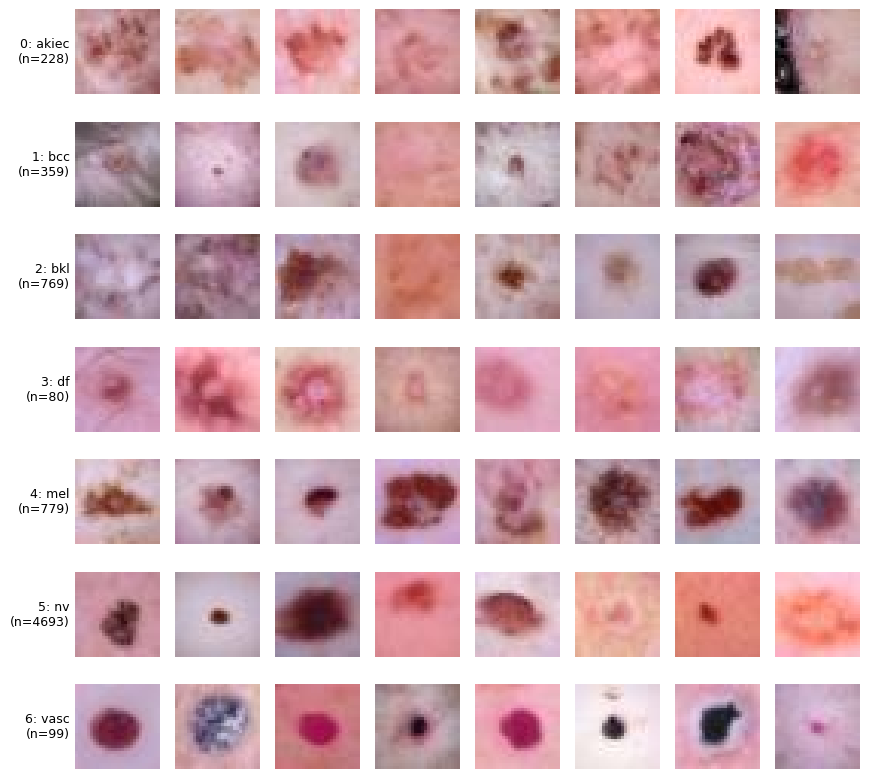

labels shape:  (7007,)
Class 0: 228: 3.3%
Class 1: 359: 5.1%
Class 2: 769: 11.0%
Class 3: 80: 1.1%
Class 4: 779: 11.1%
Class 5: 4693: 67.0%
Class 6: 99: 1.4%
shape, type, min, and max before: (7007, 28, 28, 3) uint8 0 255
shape, type, min, and max after: torch.Size([7007, 3, 28, 28]) torch.float32 tensor(-1.) tensor(1.)
torch.Size([7007, 3, 28, 28]) torch.float32 torch.Size([7007]) torch.int64


In [ ]:
set_seed(cfg["seed"])
imgs, labels = load_uint8_train_split(cfg["split_variant"], verbose=True)
show_grid(imgs, labels, per_class=8)
class_counts(labels)
print("shape, type, min, and max before:", imgs.shape, imgs.dtype, imgs.min(), imgs.max())
imgs_float = to_floats(imgs)
print("shape, type, min, and max after:", imgs_float.shape, imgs_float.dtype, imgs_float.min(), imgs_float.max())

train_x = imgs_float.to("cuda")
train_y = torch.from_numpy(labels).long().to("cuda")
print(train_x.shape, train_x.dtype, train_y.shape, train_y.dtype)




## 4. Model

The noise predictor ε_θ(x_t, t, y) is a class-conditional U-Net from `diffusers`:

- Three resolution levels, 28 → 14 → 7 and back up to 28, with 64, 128 and 128 feature maps. A fourth level does not fit a 28×28 input.
- Each level has two ResBlocks. Attention is used only at 14×14, plus the middle block at 7×7.
- The up path mirrors the down path, with skip connections between them.
- Dropout 0.1 in every ResBlock.
- `num_class_embeds = 8` creates a class embedding with rows 0–6 for the classes and row 7 for the null label. It is added to the time embedding, so every ResBlock receives both the noise level and the class.

In [ ]:
def build_unet(cfg):
    """Class-conditional U-Net: ε_θ(x_t, t, y), with y ∈ {0..6} classes + {7} null."""
    n_levels = len(cfg["block_out_channels"]) # (64, 128, 128)
    assert len(cfg["attn_levels"]) == n_levels, "one attention flag per level" # (False, True, False)

    down = tuple("AttnDownBlock2D" if a else "DownBlock2D" for a in cfg["attn_levels"])
    up   = tuple("AttnUpBlock2D"   if a else "UpBlock2D"   for a in reversed(cfg["attn_levels"]))

    return UNet2DModel(
        sample_size        = cfg["image_size"], # 28
        in_channels        = 3,
        out_channels       = 3,                       # predicts ε, same shape as the image
        block_out_channels = tuple(cfg["block_out_channels"]),
        layers_per_block   = cfg["layers_per_block"],
        down_block_types   = down,
        up_block_types     = up,                      # mirror of down
        dropout            = cfg["dropout"],
        attention_head_dim = cfg["attention_head_dim"],
        num_class_embeds   = cfg["num_classes"] + 1,  # 7 classes + null label
    )

Build the model with a fixed seed, and record the number of parameters and the library versions in `run_info.json`.

The model has 6.47 M parameters, about 5× fewer than the 35.7 M CIFAR-10 model of Milestone 1, for a dataset about 7× smaller.

In [ ]:
device = "cuda"
set_seed(cfg["seed"])         # same init every time for the same config
model = build_unet(cfg).to(device)

run_info = {
    "n_params_M": round(model.num_parameters() / 1e6, 2),
    "torch": torch.__version__,
    "diffusers": diffusers.__version__,
    "medmnist": medmnist.__version__,
}

with open(run_dir/"run_info.json", "w") as f:
      json.dump(run_info, f)
print(run_info)

{'n_params_M': 6.47, 'torch': '2.14.1+cu130', 'diffusers': '0.42.1', 'medmnist': '3.0.2'}


Speed benchmark on throwaway models: time per training step and peak GPU memory for three batch sizes, with and without mixed precision (AMP).

AMP is faster at every batch size, and memory is never the limit. With AMP, batch 128 takes about 0.21 s per step, so 40,000 steps fit in about 2.4 hours on a T4.

In [ ]:
def benchmark_step(model, batch_size, n_iters=20, amp=True, device="cuda"):
    """Average seconds per training step and peak GPU memory (GB). Updates the weights!"""
    model.train()
    opt = torch.optim.AdamW(model.parameters(), lr=1e-4)
    scaler = torch.amp.GradScaler(device, enabled=amp)
    x = torch.randn(batch_size, 3, 28, 28, device=device)
    torch.cuda.reset_peak_memory_stats()
    for i in range(n_iters + 3):
        if i == 3:                                   # first 3 iterations = warm-up
            torch.cuda.synchronize(); t0 = time.time()
        t = torch.randint(0, 1000, (batch_size,), device=device)
        y = torch.randint(0, 8, (batch_size,), device=device)
        with torch.autocast(device, dtype=torch.float16, enabled=amp):
            loss = (model(x, t, class_labels=y).sample - x).pow(2).mean()
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
    torch.cuda.synchronize()
    return (time.time() - t0) / n_iters, torch.cuda.max_memory_allocated() / 1e9

for bs in [64, 128, 256]:
    for amp in [False, True]:
        sec, mem = benchmark_step(build_unet(cfg).to(device), bs, amp=amp)   # throwaway model
        print(f"batch {bs:>3} | amp {amp!s:5} | {sec*1000:6.1f} ms/step | {mem:.2f} GB | "
              f"{3600/sec:,.0f} steps/h")

batch  64 | amp False |  178.6 ms/step | 1.66 GB | 20,155 steps/h
batch  64 | amp True  |  150.8 ms/step | 1.42 GB | 23,876 steps/h
batch 128 | amp False |  377.8 ms/step | 2.97 GB | 9,528 steps/h
batch 128 | amp True  |  214.4 ms/step | 2.48 GB | 16,793 steps/h
batch 256 | amp False |  754.2 ms/step | 5.65 GB | 4,773 steps/h
batch 256 | amp True  |  399.8 ms/step | 4.58 GB | 9,005 steps/h


In [ ]:
from diffusers import DDPMScheduler
import torch.nn.functional as F

scheduler = DDPMScheduler(
    num_train_timesteps=cfg["T"],
    beta_start=cfg["beta_start"],
    beta_end=cfg["beta_end"],
    beta_schedule="linear")


## 5. Diffusion training

The forward process and the training loss:

- `DDPMScheduler` holds the linear β schedule. `add_noise(x0, ε, t)` produces the noisy image x_t = √ᾱ_t · x_0 + √(1 − ᾱ_t) · ε in one step.
- `draw_batch` picks random training images, so the classes appear with their natural frequencies.
- `drop_labels` replaces each label by the null label with probability 0.1. The model therefore also learns to predict the noise without a class, which classifier-free guidance needs at sampling time.
- `diffusion_loss` draws a random noise level for each image, adds the noise, and returns the mean squared error between the predicted and the true noise (the DDPM loss).

In [ ]:
# choose B random images from the train set and return them and their labels
def draw_batch(B):
    idx = torch.randint(0, train_x.shape[0], (B,), device=device)
    return train_x[idx], train_y[idx]

# replaces labels in y with class 7 (null) with probability p
def drop_labels(y, p):
    drop = torch.rand(y.shape[0], device=y.device) < p
    return torch.where(drop, torch.full_like(y, cfg["null_class"]), y)

# picks a random noise level, and mixes the noise into the image at their noise level. Hides about 10% of the labels. Gets the model's estimate of the noise added, and returns the loss
def diffusion_loss(model, x0, y):
    t = torch.randint(0, cfg["T"], (x0.shape[0],), device=device)
    eps = torch.randn_like(x0)
    x_t = scheduler.add_noise(x0, eps, t)
    y_in = drop_labels(y, cfg["p_uncond"])
    with torch.autocast("cuda", dtype=torch.float16, enabled=cfg["amp"]):
        eps_hat = model(x_t, t, class_labels=y_in).sample
    return F.mse_loss(eps_hat.float(), eps)

Two more pieces:

- `ema_update` keeps an exponential moving average (EMA) of the weights, with decay 0.9995 (roughly an average over the last 2,000 steps). All sampling uses the EMA model. Milestone 1 showed how much this matters: FID 4.72 with the EMA weights, 9.79 without.
- `sample` generates images with the DDIM sampler of Milestone 1 (50 quadratic steps, η = 0) and classifier-free guidance: ε = ε_uncond + (1 + w) · (ε_cond − ε_uncond). With w = 0 this is plain conditional sampling; a larger w makes the images more typical of their class, but less varied.

In [ ]:
@torch.no_grad()
def ema_update(ema, model, step):
    d = min(cfg["ema_decay"], (1 + step) / (10 + step))
    for p_ema, p in zip(ema.parameters(), model.parameters()):
        p_ema.lerp_(p, 1 - d)     # p_ema = d·p_ema + (1−d)·p

In [ ]:
@torch.no_grad()
def sample(net, labels, w=0.0, steps=50, seed=0):
    # x is the starting noise, one 3x28x28 image per label, seeded so it is comparable across training sessions
    g = torch.Generator(device=device).manual_seed(seed)
    x = torch.randn((len(labels), 3, cfg["image_size"], cfg["image_size"]), generator=g, device=device)

    # quadratic spacing of 50 noise levels like DDIM
    seq = [int(s) for s in np.linspace(0, np.sqrt(cfg["T"] * 0.8), steps) ** 2]

    y2 = torch.cat([labels, torch.full_like(labels, cfg["null_class"])])            # real labels, then null

    def eps_fn(x, t):
        with torch.autocast("cuda", dtype=torch.float16, enabled=cfg["amp"]):
            e = net(torch.cat([x, x]), torch.cat([t, t]), class_labels=y2).sample.float()
        e_cond, e_uncond = e.chunk(2)
        return e_uncond + (1 + w) * (e_cond - e_uncond)

    xs, _ = generalized_steps(x, seq, eps_fn, scheduler.betas.to(device), eta=0.0)
    return xs[-1]                          # final images: CPU tensor, roughly in [-1, 1]

The training loop. It resumes from `latest.pt` if a checkpoint exists, so it can simply be re-run after a disconnect. At every step it:

- warms the learning rate up linearly over the first 1,000 steps,
- computes the loss on a batch of 128 images and updates the weights, with AMP and gradient clipping at 1.0,
- updates the EMA weights.

Every 500 steps it prints the loss, every 1,000 steps it saves a checkpoint, and every 5,000 steps it saves an EMA snapshot and a preview grid.

The output below is from a resumed session, in which the model had already completed its 40,000 steps.

In [ ]:
ckpt_path = run_dir / "latest.pt"
ema = copy.deepcopy(model).eval().requires_grad_(False)
opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
scaler = torch.amp.GradScaler("cuda", enabled=cfg["amp"])
preview_labels = torch.arange(cfg["num_classes"], device=device).repeat_interleave(8)
step, losses, train_sec = 0, [], 0.0

if ckpt_path.exists():  # resume
    ck = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(ck["model"])
    ema.load_state_dict(ck["ema"])
    opt.load_state_dict(ck["opt"])
    scaler.load_state_dict(ck["scaler"])
    step, losses, train_sec = ck["step"], ck["losses"], ck["train_sec"]
    print(f"resumed from step {step}")

model.train()
t_start, sec_at_start = time.time(), train_sec
while step < cfg["train_steps"]:
    for g in opt.param_groups:
      g["lr"] = cfg["lr"] * min(1.0, (step + 1) / cfg["warmup_steps"])
    loss = diffusion_loss(model, *draw_batch(cfg["batch_size"]))
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(opt); scaler.update()
    ema_update(ema, model, step)
    losses.append(loss.item()); step += 1
    train_sec = sec_at_start + (time.time() - t_start)

    if step % cfg["log_every"] == 0:
        print(f"step {step:>6} | loss {np.mean(losses[-cfg['log_every']:]):.4f} | {train_sec/3600:.2f} GPU-h")
    if step % cfg["ckpt_every"] == 0 or step == cfg["train_steps"]: #    checkpoint
        tmp = ckpt_path.with_suffix(".tmp")
        torch.save({"model": model.state_dict(), "ema": ema.state_dict(), "opt": opt.state_dict(),
                    "scaler": scaler.state_dict(), "step": step, "losses": losses,
                    "train_sec": train_sec}, tmp)
        tmp.replace(ckpt_path)
    if step % cfg["preview_every"] == 0:                            #    preview + EMA snapshot
        torch.save(ema.state_dict(), run_dir / f"ema_{step:06d}.pt")
        fig = show_grid(sample(ema, preview_labels, w=cfg["preview_w"]), preview_labels.cpu(),
                        per_class=8, title=f"EMA @ step {step}",
                        save_path=run_dir / f"preview_{step:06d}.png")
        plt.close(fig)

resumed from step 40000


## 6. Training results

Loss curve (200-step moving average, log scale). The loss falls quickly during the first few thousand steps, then decreases slowly to about 0.01, with no spikes. Its absolute value is not a quality measure, because at high noise levels the noise cannot be predicted.

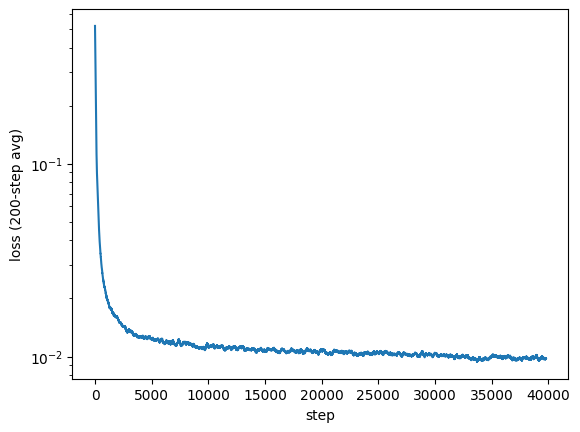

In [ ]:
k = 200  # moving-average window
plt.plot(np.convolve(losses, np.ones(k) / k, mode="valid"))
plt.xlabel("step"); plt.ylabel(f"loss ({k}-step avg)"); plt.yscale("log")
plt.savefig(run_dir / "loss_curve.png", dpi=150); plt.show()

The average loss every 500 steps, and the total training time (about 2.4 GPU-hours on a T4).

In [ ]:
ck = torch.load(run_dir / "latest.pt", map_location="cpu")
losses, every = ck["losses"], cfg["log_every"]

print(f"trained steps: {ck['step']} | GPU-hours: {ck['train_sec'] / 3600:.2f}")
for s in range(every, len(losses) + 1, every):
    print(f"step {s:>6} | loss {np.mean(losses[s - every:s]):.4f}")

trained steps: 40000 | GPU-hours: 2.42
step    500 | loss 0.2476
step   1000 | loss 0.0280
step   1500 | loss 0.0194
step   2000 | loss 0.0167
step   2500 | loss 0.0153
step   3000 | loss 0.0139
step   3500 | loss 0.0135
step   4000 | loss 0.0128
step   4500 | loss 0.0126
step   5000 | loss 0.0126
step   5500 | loss 0.0123
step   6000 | loss 0.0122
step   6500 | loss 0.0119
step   7000 | loss 0.0118
step   7500 | loss 0.0117
step   8000 | loss 0.0117
step   8500 | loss 0.0117
step   9000 | loss 0.0114
step   9500 | loss 0.0112
step  10000 | loss 0.0112
step  10500 | loss 0.0114
step  11000 | loss 0.0113
step  11500 | loss 0.0112
step  12000 | loss 0.0110
step  12500 | loss 0.0111
step  13000 | loss 0.0110
step  13500 | loss 0.0110
step  14000 | loss 0.0109
step  14500 | loss 0.0108
step  15000 | loss 0.0108
step  15500 | loss 0.0108
step  16000 | loss 0.0109
step  16500 | loss 0.0105
step  17000 | loss 0.0108
step  17500 | loss 0.0107
step  18000 | loss 0.0107
step  18500 | loss 0.0106

## 7. Generate synthetic images

Load the EMA weights saved at step 40,000. This also works in a fresh session, without re-training.

In [ ]:
def load_ema(step):
    net = build_unet(cfg).to("cuda").eval().requires_grad_(False)
    net.load_state_dict(torch.load(run_dir / f"ema_{step:06d}.pt", map_location=device))
    return net

Generate 1,000 images for each class except nv (akiec, bcc, bkl, df, mel, vasc), with guidance w = 0.3, a small guidance strength: the classifier-free guidance paper (Ho & Salimans, 2022) obtained its best FID with w = 0.1 or 0.3, depending on the dataset. As in Milestone 1:

- Images are generated in batches of 250. Batch b of class c uses the seed `gen_seed + 1000·c + b`, so every batch is reproducible on its own.
- Each batch is saved to Drive as soon as it is done: first to a temporary file, then renamed. Batches that already exist are skipped, so the loop is resumable.

In [ ]:
gen = load_ema(cfg["gen_ema_step"]) # works in a fresh session
w_tag = f"w{cfg['gen_w']:g}"
pool_dir = run_dir / f"synthetic_{w_tag}"
pool_dir.mkdir(exist_ok=True)

n_batches = math.ceil(cfg["pool_per_class"] / cfg["gen_batch"])   # 1000 / 250 = 4 batches per class
batch_secs = []
for c in cfg["pool_classes"]:
    for b in range(n_batches):
        path = pool_dir / f"c{c}_b{b:03d}.npy"
        if path.exists():
            print(f"batch c{c}_b{b:03d}.npy exists")
            continue
        n = min(cfg["gen_batch"], cfg["pool_per_class"] - b * cfg["gen_batch"])
        t0 = time.time()
        y = torch.full((n,), c, dtype=torch.long, device=device)
        x = sample(gen, y, w=cfg["gen_w"], seed=cfg["gen_seed"] + 1000 * c + b)   # 50 steps (default)
        tmp = path.with_name(path.stem + "_tmp.npy")
        np.save(tmp, to_uint8(x))   # uint8 (n, 28, 28, 3), like the real data
        tmp.replace(path)
        batch_secs.append(time.time() - t0)
        print(f"{CLASS_SHORT[c]:>5} batch {b + 1}/{n_batches} | {batch_secs[-1]:.1f}s")

akiec batch 1/4 | 15.2s
akiec batch 2/4 | 13.3s
akiec batch 3/4 | 13.6s
akiec batch 4/4 | 13.9s
  bcc batch 1/4 | 14.2s
  bcc batch 2/4 | 14.6s
  bcc batch 3/4 | 14.4s
  bcc batch 4/4 | 14.1s
  bkl batch 1/4 | 13.9s
  bkl batch 2/4 | 13.9s
  bkl batch 3/4 | 14.0s
  bkl batch 4/4 | 14.1s
   df batch 1/4 | 14.1s
   df batch 2/4 | 14.1s
   df batch 3/4 | 14.1s
   df batch 4/4 | 14.1s
  mel batch 1/4 | 14.1s
  mel batch 2/4 | 14.1s
  mel batch 3/4 | 14.1s
  mel batch 4/4 | 14.1s
 vasc batch 1/4 | 14.1s
 vasc batch 2/4 | 14.1s
 vasc batch 3/4 | 14.1s
 vasc batch 4/4 | 14.1s


Combine the batches into one file, `synthetic_pool_w0.3.npz` (images and labels), save the generation settings next to it in `synthetic_pool_w0.3.json`, and check the result: 6,000 uint8 images of size 28×28, 1,000 for each class except nv, and no exact duplicates.

In [ ]:
pool_imgs, pool_labels = [], []
for c in cfg["pool_classes"]:
    files = sorted(pool_dir.glob(f"c{c}_b[0-9][0-9][0-9].npy"))        # excludes any *_tmp.npy
    arr = np.concatenate([np.load(f) for f in files])
    pool_imgs.append(arr); pool_labels.append(np.full(len(arr), c, dtype=np.int64))
pool_imgs, pool_labels = np.concatenate(pool_imgs), np.concatenate(pool_labels)

pool_path = run_dir / f"synthetic_pool_{w_tag}.npz"
np.savez_compressed(pool_path, imgs=pool_imgs, labels=pool_labels)

meta = {"ema_step": cfg["gen_ema_step"], "w": cfg["gen_w"], "steps": 50, "eta": 0.0,
        "classes": cfg["pool_classes"], "per_class": cfg["pool_per_class"],
        "seed_rule": "gen_seed + 1000*class + batch", "gen_seed": cfg["gen_seed"],
        "split_variant": cfg["split_variant"], "n_total": int(len(pool_imgs))}
with open(run_dir / f"synthetic_pool_{w_tag}.json", "w") as f:
    json.dump(meta, f, indent=2)

In [ ]:
d = np.load(pool_path)
print(d["imgs"].shape, d["imgs"].dtype, d["imgs"].min(), d["imgs"].max())   # (6000, 28, 28, 3) uint8 0 255
print(np.bincount(d["labels"], minlength=cfg["num_classes"]))               # [1000 1000 1000 1000 1000 0 1000]
assert len({im.tobytes() for im in d["imgs"]}) == len(d["imgs"]), "exact duplicates found"


(6000, 28, 28, 3) uint8 0 255
[1000 1000 1000 1000 1000    0 1000]


## Summary

| Item | Value |
|---|---|
| Training data | DermaMNIST training split, original version: 7,007 images, 28×28 |
| Model | class-conditional U-Net, 6.47 M parameters, 7 classes + null label |
| Training | 40,000 steps, batch 128, AMP, EMA 0.9995, about 2.4 GPU-hours on a T4 |
| Sampler | DDIM, 50 quadratic steps, η = 0, classifier-free guidance w = 0.3 |
| Generated images | 1,000 each for akiec, bcc, bkl, df, mel and vasc (6,000 in total) |

- The loss decreases smoothly and the previews show clean, class-specific images by the end of training.
- The generated images are saved in `synthetic_pool_w0.3.npz`, in the same format as the real data. Part 2 uses them to top up the minority classes and retrain the classifier.